# 01 — Exploratory data analysis

PlantVillage color images are the training source: lab photographs of single leaves on a plain background, 38 crop/disease classes, from the Kaggle dataset `abdallahalidev/plantvillage-dataset`. PlantDoc is a separate field-photo test set (internet photos, cluttered backgrounds). It is not mixed into train or validation.

The instructor flagged the domain gap this notebook is here to document: a classifier can look excellent on PlantVillage and then drop on field photos. The sections below measure the dataset facts behind that gap — class imbalance, image geometry, color and brightness, and a side-by-side look at the two domains.

Run these from the repository root before executing the notebook:

```bash
python -m src.data.download
python -m src.data.splits
```

Images live in `data/raw/` (gitignored). Tables live in `data/splits/` and `data/plantdoc_label_map.csv`.


In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

here = Path.cwd().resolve()
for candidate in [here, *here.parents]:
    if (candidate / "src" / "data" / "labels.py").is_file():
        ROOT = candidate
        break
else:
    raise RuntimeError("Could not find the repository root. Open this notebook from the project directory.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.labels import (
    NUM_CLASSES,
    UNMAPPED_PLANTVILLAGE,
    crop_and_condition,
    display_crop,
    is_healthy,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 100)

PV_COLOR = "#2b8cbe"
PD_COLOR = "#e6550d"
HEALTHY_COLOR = "#2ca25f"
RNG = np.random.default_rng(42)


def load_split_tables():
    frames = []
    for name in ("train", "val", "test"):
        path = ROOT / "data" / "splits" / f"{name}.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Missing {path}. Run: python -m src.data.splits")
        frames.append(pd.read_csv(path).assign(split=name))
    plantvillage = pd.concat(frames, ignore_index=True)
    plantdoc_path = ROOT / "data" / "splits" / "plantdoc_test.csv"
    if not plantdoc_path.is_file():
        raise FileNotFoundError(f"Missing {plantdoc_path}. PlantDoc did not download.")
    plantdoc = pd.read_csv(plantdoc_path)
    for frame, name in ((plantvillage, "PlantVillage"), (plantdoc, "PlantDoc")):
        missing = [row for row in frame["path"] if not (ROOT / row).is_file()]
        if missing:
            raise FileNotFoundError(f"{len(missing)} {name} files from the CSVs are not on disk. First missing: {missing[0]}")
    return plantvillage, plantdoc


def short_label(label: str) -> str:
    crop = display_crop(label)
    _crop, condition = crop_and_condition(label)
    return f"{crop}: {condition.replace('_', ' ')}"


plantvillage, plantdoc = load_split_tables()
print(f"PlantVillage images: {len(plantvillage):,}")
print(f"PlantVillage classes: {plantvillage['label'].nunique()} (expected {NUM_CLASSES})")
print(plantvillage["split"].value_counts().rename("images").to_string())
print(f"PlantDoc field-test images: {len(plantdoc):,} across {plantdoc['label'].nunique()} mapped classes")
print(f"PlantVillage classes with no PlantDoc photos: {len(UNMAPPED_PLANTVILLAGE)}")


PlantVillage images: 54,305
PlantVillage classes: 38 (expected 38)
split
train    38013
val       8146
test      8146
PlantDoc field-test images: 2,578 across 28 mapped classes
PlantVillage classes with no PlantDoc photos: 10


## Class counts and imbalance

Accuracy on this dataset is easy to inflate. A few classes hold a large share of the images, and the smallest class is healthy potato. The split is stratified, so train, val, and test keep that same skew. Eric should report macro-F1 and per-class recall, not accuracy alone. Mayur should not treat a high overall accuracy as evidence that the rare classes are learned.


Largest class: Orange___Haunglongbing_(Citrus_greening) (5,507)
Smallest class: Potato___healthy (152)
Median class size: 1092
Imbalance ratio (largest / smallest): 36.23
Share of images in the 3 largest classes: 29.4%


,label,images,share,crop,healthy,rank
0,Orange___Haunglongbing_(Citrus_greening),5507,10.14,Orange,False,1
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.86,Tomato,False,2
2,Soybean___healthy,5090,9.37,Soybean,True,3
3,Peach___Bacterial_spot,2297,4.23,Peach,False,4
4,Tomato___Bacterial_spot,2127,3.92,Tomato,False,5
5,Tomato___Late_blight,1909,3.52,Tomato,False,6
6,Squash___Powdery_mildew,1835,3.38,Squash,False,7
7,Tomato___Septoria_leaf_spot,1771,3.26,Tomato,False,8
8,Tomato___Spider_mites Two-spotted_spider_mite,1676,3.09,Tomato,False,9
9,Apple___healthy,1645,3.03,Apple,True,10


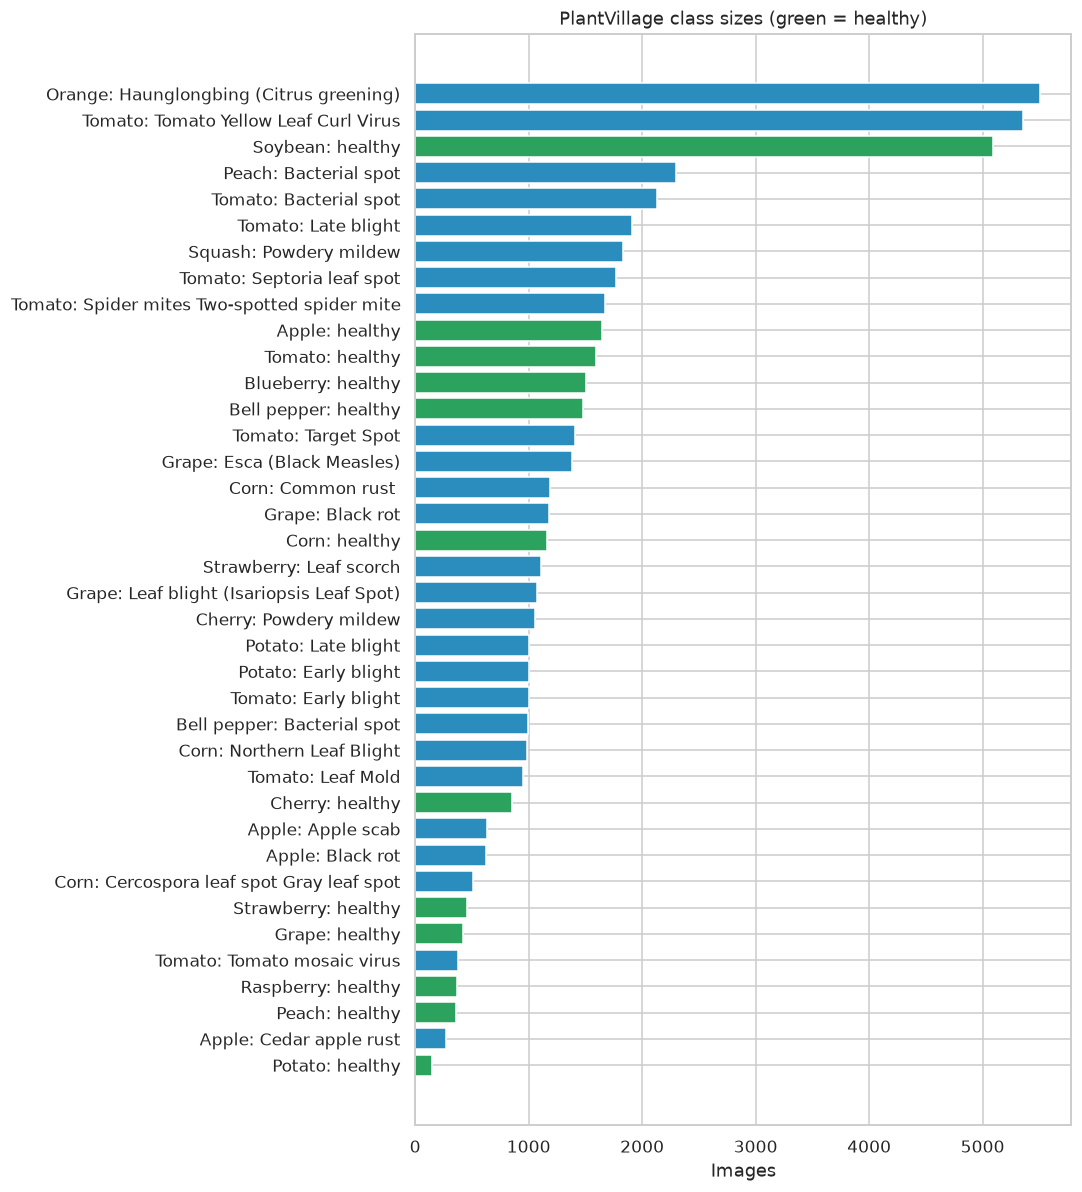

In [2]:
counts = (
    plantvillage.groupby("label")
    .size()
    .rename("images")
    .reset_index()
    .sort_values("images", ascending=False)
    .reset_index(drop=True)
)
counts["share"] = counts["images"] / counts["images"].sum()
counts["crop"] = counts["label"].map(display_crop)
counts["healthy"] = counts["label"].map(is_healthy)
counts["rank"] = np.arange(1, len(counts) + 1)

imbalance_ratio = counts["images"].max() / counts["images"].min()
top3_share = counts["images"].head(3).sum() / counts["images"].sum()
print(f"Largest class: {counts.loc[0, 'label']} ({int(counts.loc[0, 'images']):,})")
print(f"Smallest class: {counts.loc[len(counts) - 1, 'label']} ({int(counts.loc[len(counts) - 1, 'images']):,})")
print(f"Median class size: {counts['images'].median():.0f}")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.2f}")
print(f"Share of images in the 3 largest classes: {top3_share:.1%}")
display(counts.assign(share=lambda frame: (frame["share"] * 100).round(2)))

order = counts.sort_values("images", ascending=True)
bar_colors = [HEALTHY_COLOR if flag else PV_COLOR for flag in order["healthy"]]
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(order["label"].map(short_label), order["images"], color=bar_colors)
ax.set_xlabel("Images")
ax.set_title("PlantVillage class sizes (green = healthy)")
fig.tight_layout()
display(fig)
plt.close(fig)


## Do the splits keep that balance?

`src/data/splits.py` uses a stratified 70/15/15 cut with seed 42. Every class should appear in every split, and no file should appear twice. The CSVs are sorted for stable diffs. Shuffle in the training DataLoader.


In [3]:
paths = {name: set(plantvillage.loc[plantvillage["split"] == name, "path"]) for name in ("train", "val", "test")}
overlap = (paths["train"] & paths["val"]) | (paths["train"] & paths["test"]) | (paths["val"] & paths["test"])
print(f"Images in more than one split: {len(overlap)}")
wide = plantvillage.groupby(["label", "split"]).size().unstack()
fractions = wide.div(wide.sum(axis=1), axis=0)
print("Per-class split fraction, min and max across classes:")
display(fractions.agg(["min", "median", "max"]).round(3))
missing_from_a_split = int((wide == 0).any(axis=1).sum())
print(f"Classes missing from a split: {missing_from_a_split}")


Images in more than one split: 0
Per-class split fraction, min and max across classes:


split,test,train,val
min,0.148,0.697,0.149
median,0.150,0.700,0.150
max,0.151,0.702,0.151


Classes missing from a split: 0


## Image size and aspect ratio

PlantVillage leaves were captured in a controlled setup and then resized. PlantDoc photos were scraped from the web, so width, height, and aspect ratio are part of the domain gap. A model that only ever sees square 256 px lab images has to be tested on the field distribution on purpose.


Unreadable PlantVillage images: 0
Unreadable PlantDoc images: 0


,0,1
dataset,PlantVillage,PlantDoc
images,54305,2578
width_median,256.0,800.0
height_median,256.0,667.0
width_min,256,115
width_max,256,6000
height_min,256,69
height_max,256,6000
aspect_median,1.0,1.333
aspect_p05,1.0,0.667


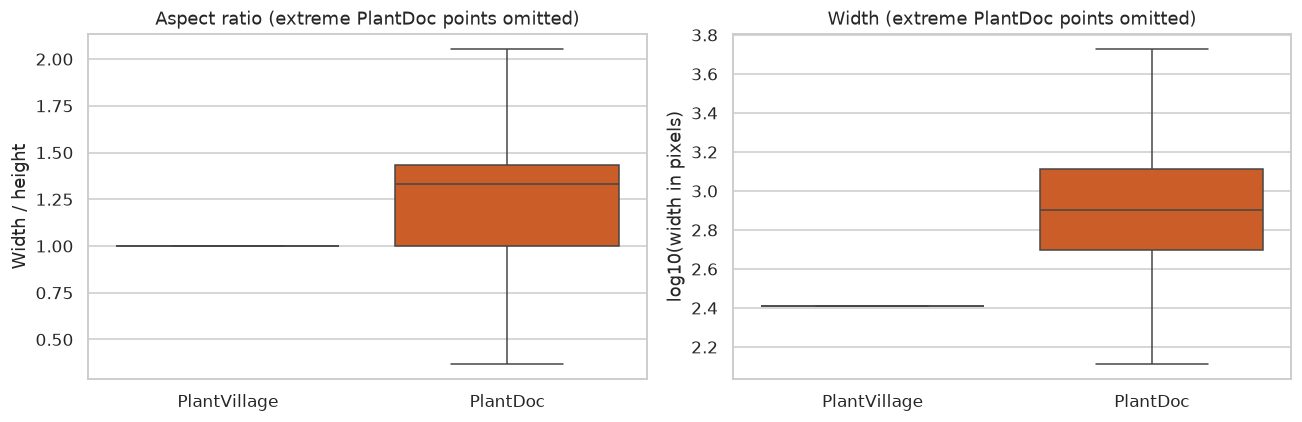

In [4]:
def scan_geometry(paths):
    widths, heights, modes, bytes_ = [], [], [], []
    failed = 0
    for raw in paths:
        path = ROOT / raw
        try:
            with Image.open(path) as image:
                width, height = image.size
                mode = image.mode
        except OSError:
            failed += 1
            continue
        widths.append(width)
        heights.append(height)
        modes.append(mode)
        bytes_.append(path.stat().st_size)
    frame = pd.DataFrame({"width": widths, "height": heights, "mode": modes, "bytes": bytes_})
    frame["aspect"] = frame["width"] / frame["height"]
    return frame, failed


pv_geom, pv_failed = scan_geometry(plantvillage["path"])
pd_geom, pd_failed = scan_geometry(plantdoc["path"])
print(f"Unreadable PlantVillage images: {pv_failed}")
print(f"Unreadable PlantDoc images: {pd_failed}")


def geometry_summary(frame, name):
    square_256 = ((frame["width"] == 256) & (frame["height"] == 256)).mean()
    return {
        "dataset": name,
        "images": len(frame),
        "width_median": frame["width"].median(),
        "height_median": frame["height"].median(),
        "width_min": int(frame["width"].min()),
        "width_max": int(frame["width"].max()),
        "height_min": int(frame["height"].min()),
        "height_max": int(frame["height"].max()),
        "aspect_median": round(float(frame["aspect"].median()), 3),
        "aspect_p05": round(float(frame["aspect"].quantile(0.05)), 3),
        "aspect_p95": round(float(frame["aspect"].quantile(0.95)), 3),
        "share_256x256": round(float(square_256), 4),
        "file_kb_median": round(frame["bytes"].median() / 1024, 1),
        "modes": ", ".join(f"{mode}={count}" for mode, count in frame["mode"].value_counts().items()),
    }


geometry = pd.DataFrame([geometry_summary(pv_geom, "PlantVillage"), geometry_summary(pd_geom, "PlantDoc")])
display(geometry.T)

geo_plot = pd.concat(
    [pv_geom.assign(dataset="PlantVillage"), pd_geom.assign(dataset="PlantDoc")],
    ignore_index=True,
)
geo_plot["log10_width"] = np.log10(geo_plot["width"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(
    data=geo_plot,
    x="dataset",
    y="aspect",
    hue="dataset",
    palette={"PlantVillage": PV_COLOR, "PlantDoc": PD_COLOR},
    legend=False,
    showfliers=False,
    ax=axes[0],
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Width / height")
axes[0].set_title("Aspect ratio (extreme PlantDoc points omitted)")
sns.boxplot(
    data=geo_plot,
    x="dataset",
    y="log10_width",
    hue="dataset",
    palette={"PlantVillage": PV_COLOR, "PlantDoc": PD_COLOR},
    legend=False,
    showfliers=False,
    ax=axes[1],
)
axes[1].set_xlabel("")
axes[1].set_ylabel("log10(width in pixels)")
axes[1].set_title("Width (extreme PlantDoc points omitted)")
fig.tight_layout()
display(fig)
plt.close(fig)


## One example from each class

These are lab frames: one leaf, centered, plain background. Within a class the photos often look like repeats of the same shoot (several angles of one leaf). The 70/15/15 split is image-level, which is what the project asked for, so those repeats can land in both train and test. That makes the PlantVillage test score an optimistic lab number. PlantDoc does not share those leaves.


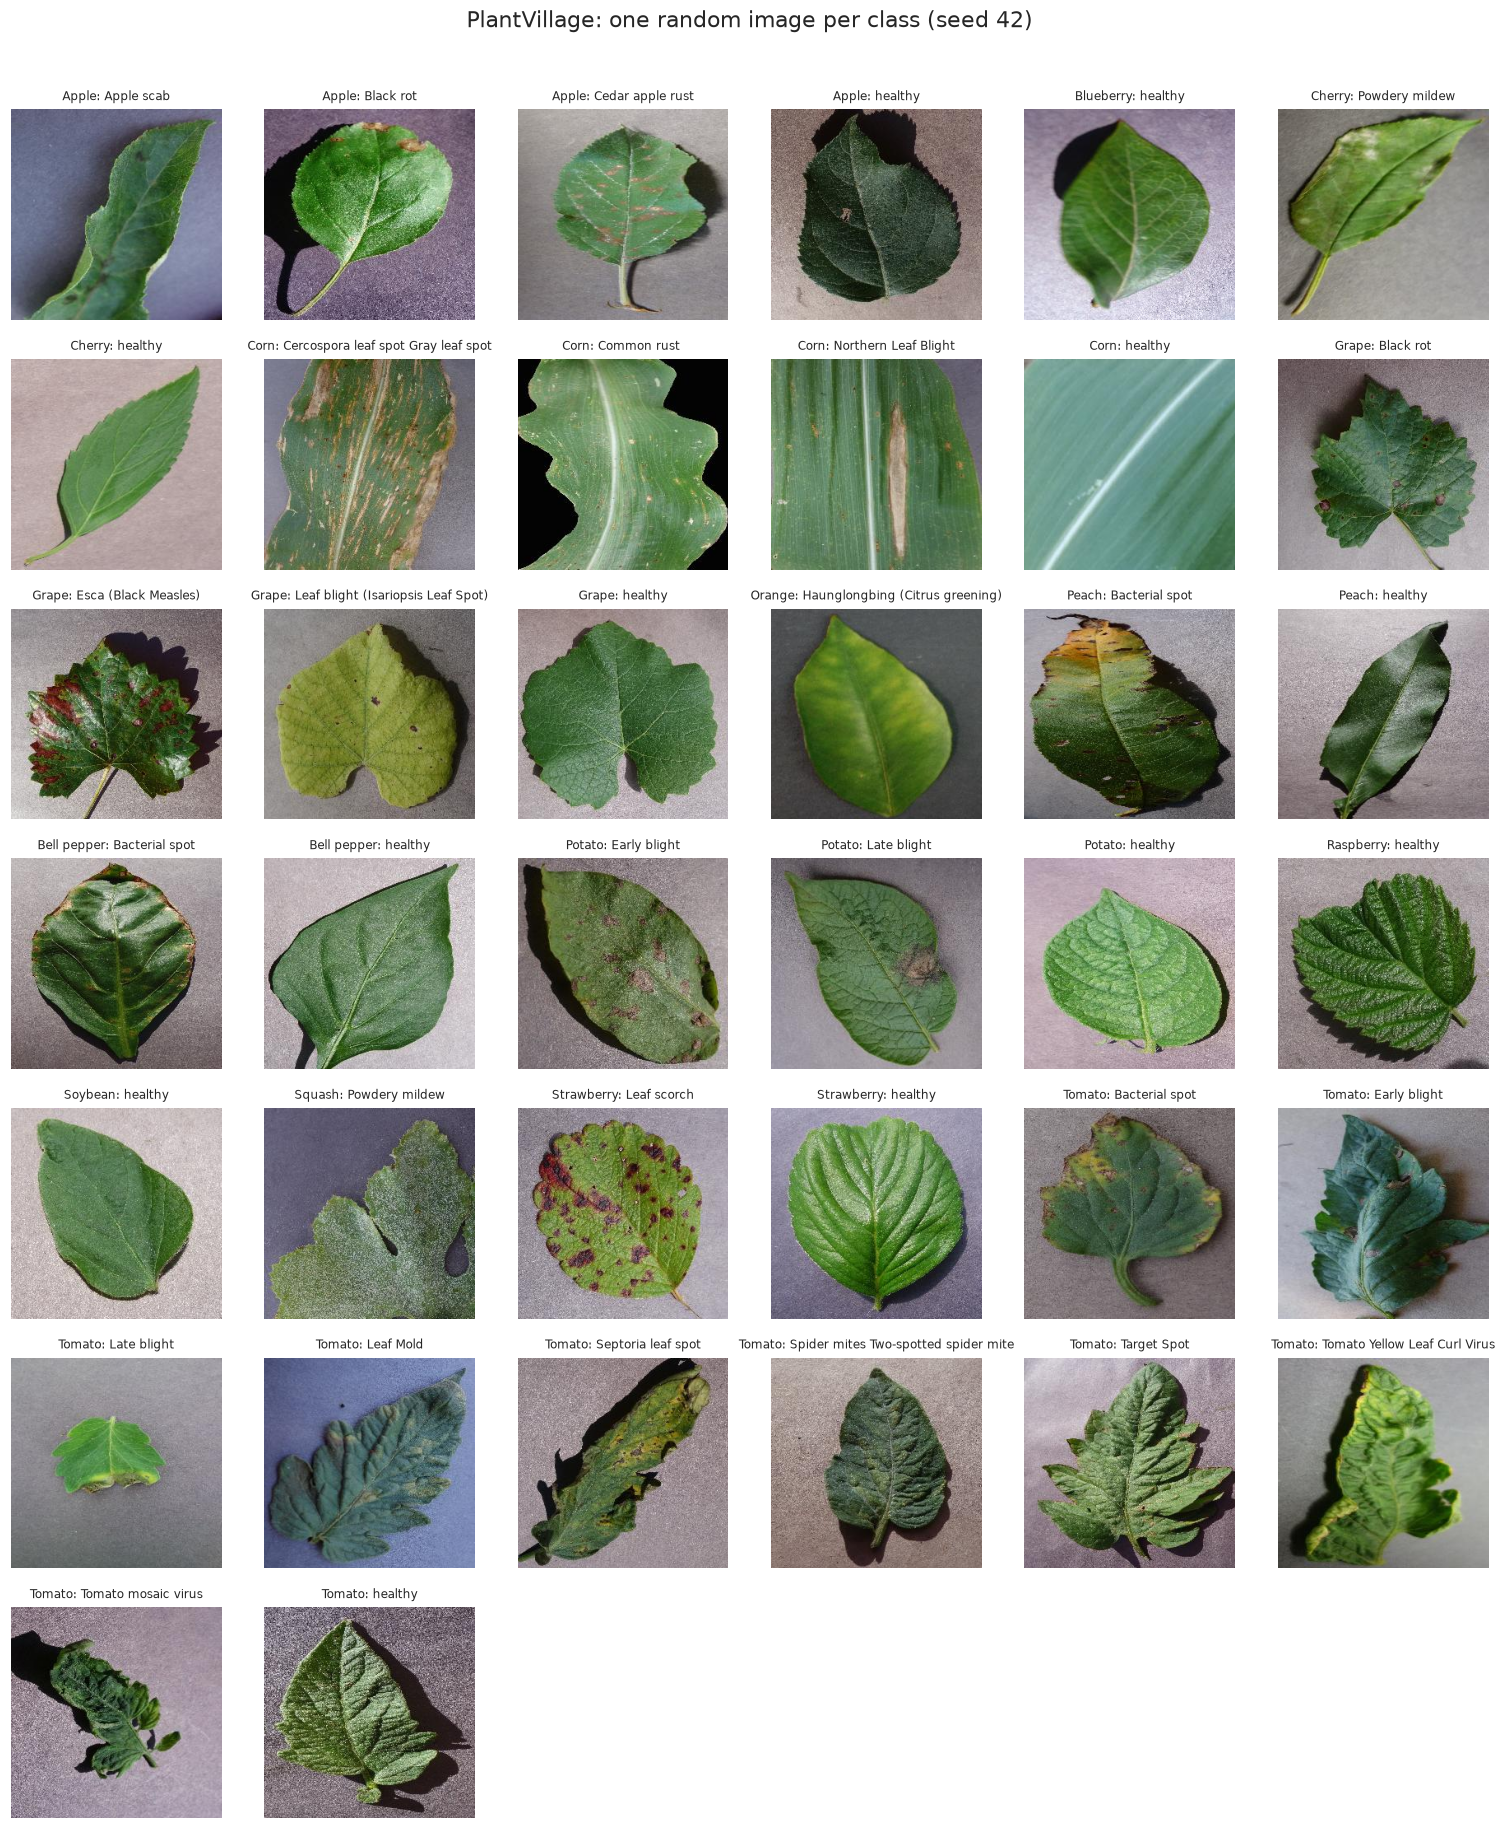

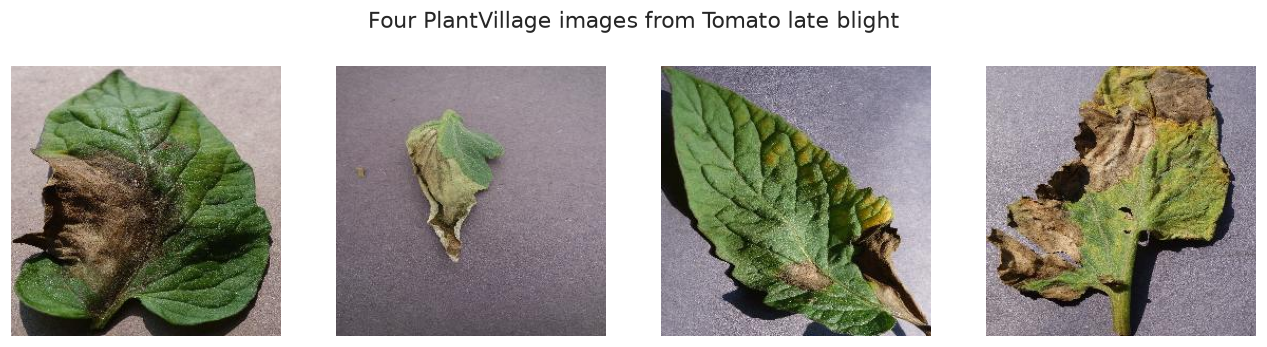

In [5]:
def choose_one(frame, label):
    pool = frame.loc[frame["label"] == label, "path"].to_numpy()
    return str(RNG.choice(pool))


labels = sorted(plantvillage["label"].unique())
columns = 6
rows = int(np.ceil(len(labels) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(14, 2.35 * rows))
for axis, label in zip(axes.ravel(), labels):
    image = Image.open(ROOT / choose_one(plantvillage, label)).convert("RGB")
    axis.imshow(image)
    axis.set_title(short_label(label), fontsize=8)
    axis.axis("off")
for axis in axes.ravel()[len(labels) :]:
    axis.axis("off")
fig.suptitle("PlantVillage: one random image per class (seed 42)", y=1.01)
fig.tight_layout()
display(fig)
plt.close(fig)

# Four shots from one class, to show how little a lab class varies.
focus = "Tomato___Late_blight"
pool = plantvillage.loc[plantvillage["label"] == focus, "path"].to_numpy()
picks = RNG.choice(pool, size=4, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for axis, raw in zip(axes, picks):
    axis.imshow(Image.open(ROOT / raw).convert("RGB"))
    axis.axis("off")
fig.suptitle("Four PlantVillage images from Tomato late blight")
fig.tight_layout()
display(fig)
plt.close(fig)


## Per-crop breakdown

The folder name is `crop___condition`. Fourteen crops are not equally represented, and several crops have only a healthy class or only a diseased class. Corn, peach, cherry, potato, and strawberry are the easy places to misread a PlantDoc score: PlantDoc is missing the matching healthy or diseased folder, so those PlantVillage classes have no field-photo test. See `data/plantdoc_label_map.csv`.


,crop,images,classes,healthy_images,diseased_images,healthy_share
0,Tomato,18160,10,1591,16569,0.088
1,Orange,5507,1,0,5507,0.000
2,Soybean,5090,1,5090,0,1.000
3,Grape,4062,4,423,3639,0.104
4,Corn,3852,4,1162,2690,0.302
5,Apple,3171,4,1645,1526,0.519
6,Peach,2657,2,360,2297,0.135
7,Bell pepper,2475,2,1478,997,0.597
8,Potato,2152,3,152,2000,0.071
9,Cherry,1906,2,854,1052,0.448


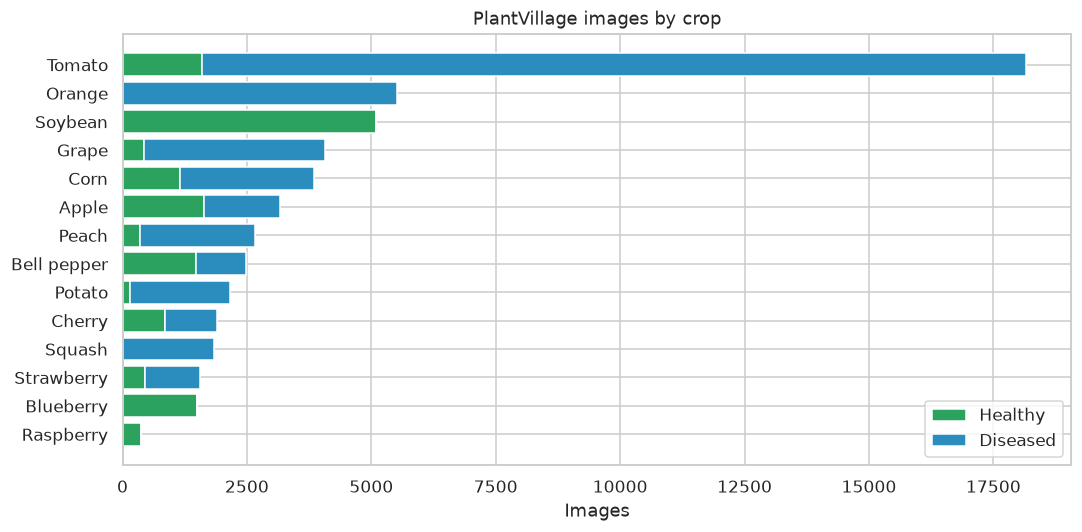

Unmapped PlantVillage classes (no PlantDoc field photos):


,plantvillage_label,notes
0,Apple___Black_rot,No apple black-rot class in PlantDoc.
1,Cherry_(including_sour)___Powdery_mildew,PlantDoc cherry images are healthy leaves only.
2,Corn_(maize)___healthy,PlantDoc has diseased corn leaves but no healthy corn class.
3,Grape___Esca_(Black_Measles),No esca / black-measles class in PlantDoc.
4,Grape___Leaf_blight_(Isariopsis_Leaf_Spot),No grape leaf-blight class in PlantDoc.
5,Orange___Haunglongbing_(Citrus_greening),PlantDoc does not include citrus. Spelling Haunglongbing is the dataset's.
6,Peach___Bacterial_spot,PlantDoc peach images are healthy leaves only.
7,Potato___healthy,PlantDoc has early and late blight but no healthy potato class.
8,Strawberry___Leaf_scorch,"PlantDoc strawberry images are healthy leaves, not leaf scorch."
9,Tomato___Target_Spot,No tomato target-spot class in PlantDoc.


In [6]:
crop_rows = plantvillage.copy()
crop_rows["crop"] = crop_rows["label"].map(display_crop)
crop_rows["healthy"] = crop_rows["label"].map(is_healthy)
per_crop = (
    crop_rows.groupby("crop")
    .agg(
        images=("path", "size"),
        classes=("label", "nunique"),
        healthy_images=("healthy", "sum"),
    )
    .reset_index()
    .sort_values("images", ascending=False)
)
per_crop["diseased_images"] = per_crop["images"] - per_crop["healthy_images"]
per_crop["healthy_share"] = (per_crop["healthy_images"] / per_crop["images"]).round(3)
display(per_crop.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 5))
plot_crop = per_crop.sort_values("images", ascending=True)
ax.barh(plot_crop["crop"], plot_crop["healthy_images"], color=HEALTHY_COLOR, label="Healthy")
ax.barh(
    plot_crop["crop"],
    plot_crop["diseased_images"],
    left=plot_crop["healthy_images"],
    color=PV_COLOR,
    label="Diseased",
)
ax.set_xlabel("Images")
ax.set_title("PlantVillage images by crop")
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

label_map = pd.read_csv(ROOT / "data" / "plantdoc_label_map.csv")
print("Unmapped PlantVillage classes (no PlantDoc field photos):")
display(label_map.loc[label_map["status"] == "unmapped", ["plantvillage_label", "notes"]].reset_index(drop=True))


## Color and brightness

Lab leaves are evenly lit. Field photos are not. The numbers below are from 25 images per class (seed 42), resized to 96 px on the long side only for the statistic. Geometry above used every image.


brightness        saturation           red          green         \
                 median    std     median   std  median    std  median    std   
dataset                                                                         
PlantDoc         110.13  41.49       0.40  0.17  112.53  45.07  133.58  39.11   
PlantVillage     117.84  18.09       0.25  0.07  119.75  19.27  125.91  18.99   

                blue         
              median    std  
dataset                      
PlantDoc       87.36  46.63  
PlantVillage  108.73  19.76

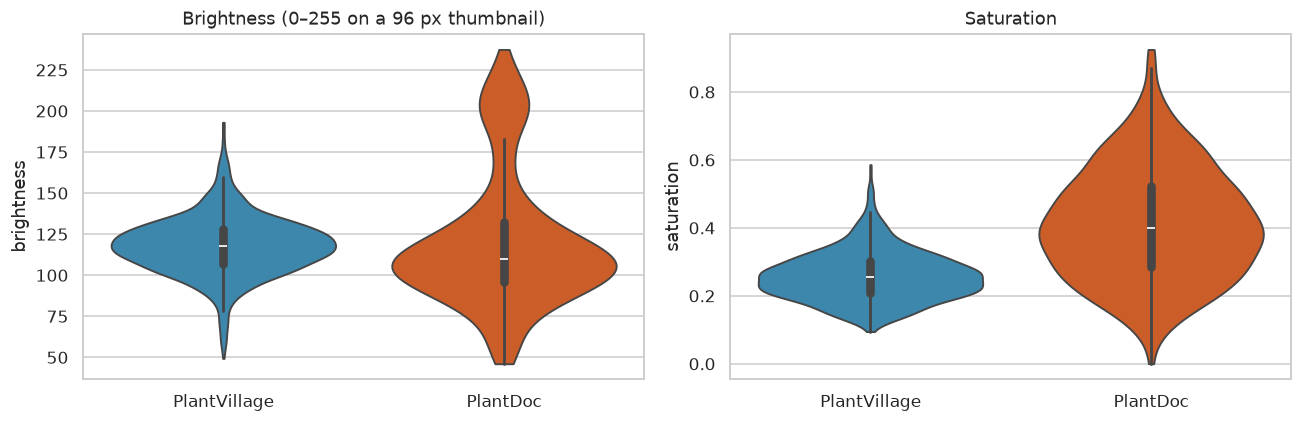

In [7]:
def sample_paths(frame, per_class):
    chosen = []
    for _label, group in frame.groupby("label"):
        pool = group["path"].to_numpy()
        take = min(per_class, len(pool))
        chosen.extend(RNG.choice(pool, size=take, replace=False).tolist())
    return chosen


def color_stats(paths, dataset):
    rows = []
    for raw in paths:
        with Image.open(ROOT / raw) as image:
            image = image.convert("RGB")
            image.thumbnail((96, 96))
            pixels = np.asarray(image, dtype=np.float32)
        mean_rgb = pixels.mean(axis=(0, 1))
        peak = pixels.max(axis=2)
        floor = pixels.min(axis=2)
        saturation = np.where(peak <= 0, 0, (peak - floor) / np.maximum(peak, 1e-6)).mean()
        rows.append(
            {
                "dataset": dataset,
                "brightness": float(pixels.mean()),
                "saturation": float(saturation),
                "red": float(mean_rgb[0]),
                "green": float(mean_rgb[1]),
                "blue": float(mean_rgb[2]),
            }
        )
    return pd.DataFrame(rows)


color = pd.concat(
    [
        color_stats(sample_paths(plantvillage, 25), "PlantVillage"),
        color_stats(sample_paths(plantdoc, 25), "PlantDoc"),
    ],
    ignore_index=True,
)
summary = color.groupby("dataset")[["brightness", "saturation", "red", "green", "blue"]].agg(["median", "std"]).round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.violinplot(data=color, x="dataset", y="brightness", hue="dataset", palette={"PlantVillage": PV_COLOR, "PlantDoc": PD_COLOR}, legend=False, ax=axes[0], cut=0)
axes[0].set_title("Brightness (0–255 on a 96 px thumbnail)")
axes[0].set_xlabel("")
sns.violinplot(data=color, x="dataset", y="saturation", hue="dataset", palette={"PlantVillage": PV_COLOR, "PlantDoc": PD_COLOR}, legend=False, ax=axes[1], cut=0)
axes[1].set_title("Saturation")
axes[1].set_xlabel("")
fig.tight_layout()
display(fig)
plt.close(fig)


## PlantVillage vs PlantDoc

Same label, different picture. The top row is the lab leaf the model trains on. The bottom row is a PlantDoc photo mapped to that label. Background, scale, and lighting change; the disease name does not.


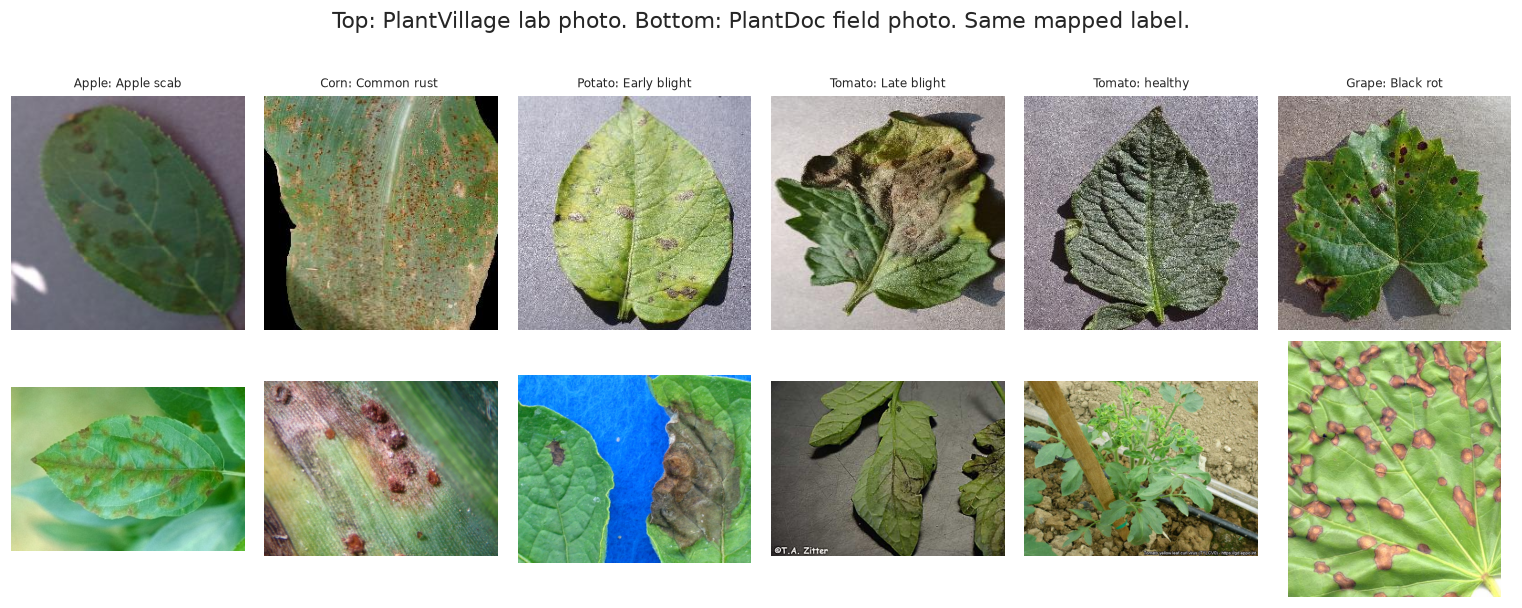

In [8]:
pairs = [
    "Apple___Apple_scab",
    "Corn_(maize)___Common_rust_",
    "Potato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___healthy",
    "Grape___Black_rot",
]
fig, axes = plt.subplots(2, len(pairs), figsize=(14, 5.4))
for column, label in enumerate(pairs):
    for row, frame in enumerate((plantvillage, plantdoc)):
        image = Image.open(ROOT / choose_one(frame, label)).convert("RGB")
        axes[row, column].imshow(image)
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(short_label(label), fontsize=8)
fig.suptitle("Top: PlantVillage lab photo. Bottom: PlantDoc field photo. Same mapped label.", y=1.02)
fig.tight_layout()
display(fig)
plt.close(fig)


## Measured on this run

- PlantVillage: **54,305** images, **38** classes. Every image is **256×256** (54,304 RGB, 1 RGBA). Median file size 16 KB.
- Stratified split, seed 42: **38,013 / 8,146 / 8,146** (70/15/15). No path is in two splits. Every class is in every split, and the train share per class stays between 69.7% and 70.2%.
- Largest class: `Orange___Haunglongbing_(Citrus_greening)`, **5,507** (the dataset spelling of citrus greening). Smallest: `Potato___healthy`, **152**. Imbalance ratio **36.2**. Median class size **1,092**. The three largest classes are **29.4%** of the images.
- Tomato alone is 18,160 images across 10 classes. Orange, soybean, squash, blueberry, and raspberry have only one condition each.
- PlantDoc field test: **2,578** images mapped onto **28** classes. Widths run from 115 to 6,000 px (median about 800×667). Median aspect ratio 1.33. None of them are 256×256. Median file size 128 KB.
- On a 25-per-class sample, brightness is centered near 110–118 in both sets, but the spread is about 18 on PlantVillage and about 41 on PlantDoc. Saturation median is 0.25 in the lab set and 0.40 in the field set.
- Ten PlantVillage classes have no PlantDoc photos. They are listed as `unmapped` in `data/plantdoc_label_map.csv`.

## Notes for modeling and evaluation

PlantVillage is a lab dataset. Most frames are square, evenly lit, and show one leaf on a uniform background. A CNN can score very high by using that background and the repeated views of the same leaf, then miss the disease when the photo is a hand, a whole plant, or a different crop stage. That is the drop the instructor described. Published work on PlantDoc (Singh et al., CoDS-COMAD 2020) built the field set for this reason: PlantVillage accuracy does not transfer to in-the-wild leaves. Hughes and Salathé (arXiv:1511.08060) describe the original controlled collection.

What this means for the team:

- **Mayur:** train only on `data/splits/train.csv`. Use `val` to choose between the baseline CNN, ResNet50, and EfficientNet. The loader in `src.data.dataset` already applies 224 px ImageNet normalization, with crop/flip/rotation/color jitter on train and a center crop on val and test. Augmentation does not turn lab images into field photos. Do not train on PlantDoc, and do not pick the winning model by its PlantDoc score.
- **Eric:** report PlantVillage `test.csv` and `plantdoc_test.csv` as two evaluations. Lead with macro-F1 and per-class recall. Accuracy will track the big classes (citrus greening, soybean healthy, tomato yellow leaf curl). Ten PlantVillage classes have no field photos; they are `unmapped` in `data/plantdoc_label_map.csv` and are absent from the PlantDoc CSV. Say that explicitly so a missing class is not confused with a failed class.
- **Both:** the PlantVillage split is image-level. Treat that test number as an in-lab ceiling, and the PlantDoc number as the check on whether the model learned the disease.


In [9]:
from src.data.dataset import build_transforms, make_dataloader, PlantDiseaseDataset

train_ds = PlantDiseaseDataset(ROOT / "data" / "splits" / "train.csv", transform=build_transforms("train"))
batch_images, batch_labels = next(iter(make_dataloader(train_ds, batch_size=8, shuffle=True)))
print("train batch:", tuple(batch_images.shape), batch_images.dtype)
print(f"normalized mean {batch_images.mean().item():.3f}, std {batch_images.std().item():.3f}")
print("batch labels:", [train_ds.idx_to_class[int(index)] for index in batch_labels])

plantdoc_ds = PlantDiseaseDataset(ROOT / "data" / "splits" / "plantdoc_test.csv", transform=build_transforms("plantdoc"))
field_image, field_label = plantdoc_ds[0]
print("plantdoc tensor:", tuple(field_image.shape), "index", int(field_label), plantdoc_ds.idx_to_class[int(field_label)])
print("class index 0:", train_ds.classes[0])
print("num classes:", len(train_ds.classes))


train batch: (8, 3, 224, 224) torch.float32
normalized mean -0.113, std 0.874
batch labels: ['Tomato___Late_blight', 'Peach___Bacterial_spot', 'Pepper,_bell___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Tomato___Septoria_leaf_spot', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)']
plantdoc tensor: (3, 224, 224) index 0 Apple___Apple_scab
class index 0: Apple___Apple_scab
num classes: 38
